# Topic Modeling — Menentukan Aspek Review Shopee (BERTopic)

Notebook ini menjalankan BERTopic ke data review Shopee yang sudah bersih (`data/processed/shopee_reviews_clean.csv`), untuk menemukan topik/aspek yang muncul secara natural dari data.

## 0. Install & Import Library

In [2]:
pip install bertopic sentence-transformers umap-learn hdbscan

  Using cached scikit_learn-1.9.1-cp312-cp312-win_amd64.whl.metadata (9.3 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached transformers-5.17.0-py3-none-any.whl.metadata (32 kB)
  Using cached tokenizers-0.23.2-cp310-abi3-win_amd64.whl.metadata (10 kB)
  Using cached torch-2.14.0-cp312-cp312-win_amd64.whl.metadata (38 kB)
  Using cached scipy-1.18.1-cp312-cp312-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)
  Using cached hf_xet-1.6.0-cp38-abi3-win_amd64.whl.metadata (4.9 kB)
  Using cached httpx-0.28.1-py3-none-any.whl.metadata (7.1 kB)
  Using cached pyyaml-6.0.3-cp312-cp312-win_amd64.whl.metadata (2.4 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
  Using cached narwhals-2.26.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached setuptools-84.0.0-py3-none-a


[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from bertopic import BERTopic
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import CountVectorizer


d:\Bootcamp\Final Project\final-project-shopee\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load Data Bersih

In [4]:
PROCESSED_PATH = "../data/processed/shopee_reviews_clean.csv"

df = pd.read_csv(PROCESSED_PATH)
print(f"Jumlah review: {len(df)}")
df.head()


Jumlah review: 6176


,reviewId,content,score,thumbsUpCount,at,appVersion
0,2d900116-95db-4727-9377-d92f4d774d3b,aplikasi ke * ntol iklan nya maksa banget anjg...,1,8,2026-09-04 12:30:16,3.81.32
1,5736f990-1306-4c0e-983b-3a5a9b131652,terus kembangkan dan lebih di permudah,5,0,2026-08-29 18:26:44,3.81.30
2,181fa0b5-15f4-4936-aea5-fd92651ce800,"sjopee sekarang paling mantap,",5,2,2026-08-29 18:26:18,3.38.34
3,1ac3fcdf-4ee7-4522-80e9-0779c8cea6e9,iklan mu sangat menjijikan dan kamu sering mem...,1,8,2026-08-29 18:25:21,3.80.37
4,b7e72be3-e537-4ec3-8b18-a80f750ab125,"pengiriman lama sampai, bahkan barang yang di ...",4,5,2026-08-29 18:22:19,3.81.30


In [5]:
docs = df["content"].astype(str).tolist()
print(f"Total dokumen untuk topic modeling: {len(docs)}")


Total dokumen untuk topic modeling: 6176


## 2. Embedding Model

Untuk topic modeling, dipakai **sentence embedding multilingual** (`paraphrase-multilingual-MiniLM-L12-v2`), bukan IndoBERT yang nanti dipakai khusus untuk tahap klasifikasi ABSA. Model ini dipilih karena BERTopic butuh embedding berbasis kalimat (sentence-level) yang sudah dioptimalkan untuk mengukur kemiripan makna, dan mendukung bahasa Indonesia dengan baik.

In [6]:
embedding_model = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")
embeddings = embedding_model.encode(docs, show_progress_bar=True)


Batches: 100%|██████████| 193/193 [00:26<00:00,  7.23it/s]


## 3. Stopword Bahasa Indonesia untuk Representasi Topik

Stopword di sini HANYA dipakai untuk membersihkan kata yang muncul di representasi topik (supaya nama topik tidak didominasi kata seperti "yang", "dan", "di") — bukan untuk mengubah teks aslinya yang dipakai untuk embedding/labeling.

In [7]:
indonesian_stopwords = [
    "yang", "dan", "di", "ke", "dari", "ini", "itu", "ada", "ya", "aja", "juga",
    "untuk", "tidak", "dengan", "saya", "nya", "gak", "ga", "tapi", "lagi", "mau",
    "sudah", "udah", "jadi", "banget", "bgt", "sangat", "apa", "kalau", "kalo",
    "atau", "karena", "krn", "bisa", "akan", "harus", "saat", "waktu", "masih",
    "lebih", "kurang", "sekali", "banyak", "sedikit", "semua", "hanya", "cuma",
    "aku", "kamu", "kita", "kami", "dia", "mereka", "nih", "deh", "sih", "dong",
    "kok", "loh", "lah", "the", "and", "is", "in", "to", "for", "of", "on",
]

vectorizer_model = CountVectorizer(stop_words=indonesian_stopwords, ngram_range=(1, 2))


## 4. Fit BERTopic

In [8]:
topic_model = BERTopic(
    embedding_model=embedding_model,
    vectorizer_model=vectorizer_model,
    language="multilingual",
    calculate_probabilities=False,
    verbose=True,
)

topics, _ = topic_model.fit_transform(docs, embeddings)

df["topic"] = topics
print(f"Jumlah topik ditemukan (termasuk outlier -1): {len(set(topics))}")


2026-09-26 21:58:54,365 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-09-26 21:59:15,656 - BERTopic - Dimensionality - Completed ✓
2026-09-26 21:59:15,656 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-09-26 21:59:15,804 - BERTopic - Cluster - Completed ✓
2026-09-26 21:59:15,810 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-09-26 21:59:16,081 - BERTopic - Representation - Completed ✓


Jumlah topik ditemukan (termasuk outlier -1): 87


## 5. Inspeksi Topik

Topik `-1` adalah outlier (dokumen yang tidak cukup mirip dengan cluster manapun) — ini normal terjadi di BERTopic, biasanya berisi review yang terlalu unik/pendek/ambigu.

In [9]:
topic_info = topic_model.get_topic_info()
topic_info.head(20)


,Topic,Count,Name,Representation,Representative_Docs
0,-1,2245,-1_shopee_barang_enggak_belanja,"[shopee, barang, enggak, belanja, sampai, harg...",[malas sekali sekarang beli produk harus 120rb...
1,0,523,0_iklan_iklannya_maksa_masuk,"[iklan, iklannya, maksa, masuk, iklan shopee, ...","[kalau buat iklan jangan maksa dong!!, bagus s..."
2,1,216,1_aplikasi_aplikasi shopee_aplikasi bagus_apli...,"[aplikasi, aplikasi shopee, aplikasi bagus, ap...",[Aplikasi Shopee sangat membantu untuk kita be...
3,2,179,2_bagus_baik_baik bagus_semoga,"[bagus, baik, baik bagus, semoga, bagus suka, ...","[untuk saat ini sangat bagus, bagus sekali 🏆 🏆..."
4,3,118,3_penjual_toko_pembeli_barang,"[penjual, toko, pembeli, barang, seller, penge...",[di shopee_id halo shope dan team RR shopee. j...
5,4,95,4_akun_password_nomor_akun baru,"[akun, password, nomor, akun baru, login, baru...","[ini kenapa, aku lupa password buat masuk akun..."
6,5,92,5_aplikasi_aplikasi jelek_jelek_aplikasi buruk,"[aplikasi, aplikasi jelek, jelek, aplikasi bur...","[aplikasi ini sangat jelek, aplikasi terlemot ..."
7,6,90,6_mantap_bang_pokoknya_percaya,"[mantap, bang, pokoknya, percaya, benar, semog...",[SPINJAM super cepat super ringan super real.....
8,7,89,7_shopee_shopee memang_shopee shopee_mantap,"[shopee, shopee memang, shopee shopee, mantap,...","[Pokok nya puas.. Shopee memang mantap, shopee..."
9,8,88,8_membantu_membantu membantu_bagus membantu_me...,"[membantu, membantu membantu, bagus membantu, ...","[sangat membantu saya sekali, sangat membantu ..."


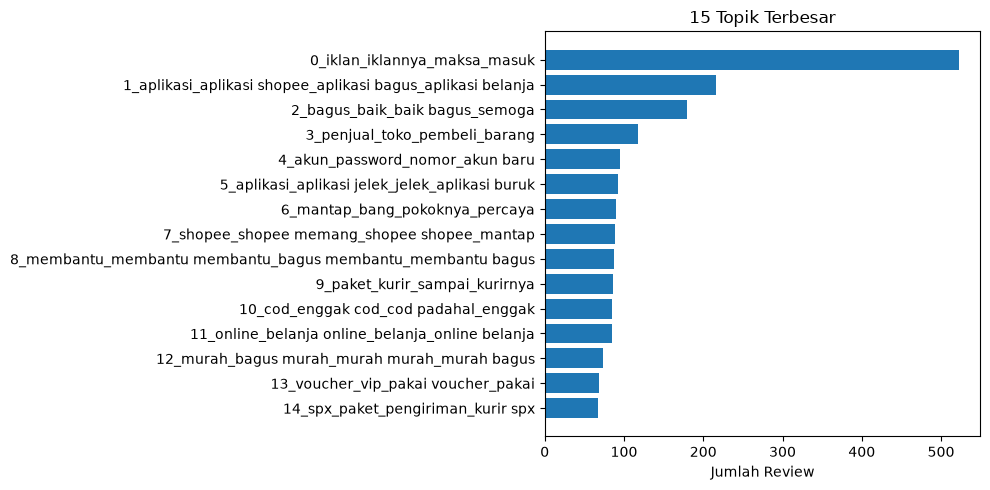

In [10]:
# distribusi jumlah dokumen per topik (untuk lihat topik mana yang dominan)
plt.figure(figsize=(10, 5))
topic_info_sorted = topic_info[topic_info["Topic"] != -1].sort_values("Count", ascending=False).head(15)
plt.barh(topic_info_sorted["Name"], topic_info_sorted["Count"])
plt.xlabel("Jumlah Review")
plt.title("15 Topik Terbesar")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


### 5.1 Lihat Kata Kunci per Topik

In [11]:
N_TOP_TOPICS = 15

for topic_id in topic_info[topic_info["Topic"] != -1]["Topic"].head(N_TOP_TOPICS):
    words = topic_model.get_topic(topic_id)
    top_words = ", ".join([w for w, _ in words[:8]])
    print(f"Topic {topic_id}: {top_words}")


Topic 0: iklan, iklannya, maksa, masuk, iklan shopee, apk, ganggu, aplikasi
Topic 1: aplikasi, aplikasi shopee, aplikasi bagus, aplikasi belanja, belanja, berbelanja, aplikasi membantu, online
Topic 2: bagus, baik, baik bagus, semoga, bagus suka, sejauh, keren, bagus bagus
Topic 3: penjual, toko, pembeli, barang, seller, pengembalian, pihak, bukti
Topic 4: akun, password, nomor, akun baru, login, baru, lupa, enggak
Topic 5: aplikasi, aplikasi jelek, jelek, aplikasi buruk, bahkan, enggak, agres id, agres
Topic 6: mantap, bang, pokoknya, percaya, benar, semoga, menari, super
Topic 7: shopee, shopee memang, shopee shopee, mantap, keren, pokoknya, memang, suka
Topic 8: membantu, membantu membantu, bagus membantu, membantu bagus, ok membantu, membantu mantap, mantap membantu, membantu ok
Topic 9: paket, kurir, sampai, kurirnya, datang, hari, tiba, agustus
Topic 10: cod, enggak cod, cod padahal, enggak, bayar, kenapa, sekarang, pembayaran cod
Topic 11: online, belanja online, belanja, online

Topik yang jelas dan actionable (jadi kandidat aspek):

Topic 0 → Iklan (iklan, iklannya, maksa, ganggu)
Topic 3 → Penjual/Retur (penjual, toko, pembeli, seller, pengembalian, bukti)
Topic 4 → Akun & Login (akun, password, nomor, login, lupa)
Topic 9 + Topic 14 → Pengiriman/Kurir (paket, kurir, sampai, spx, lambat) — ini dua topik yang sebenarnya sama, cuma beda kata kunci (SPX itu nama ekspedisi Shopee)
Topic 10 → Pembayaran/COD (cod, bayar, pembayaran)
Topic 12 → Harga (murah, berkualitas)
Topic 13 → Promo/Voucher (voucher, vip, pakai voucher)

Iklan
Pengiriman/Kurir
Penjual & Kualitas Barang/Retur (termasuk refund)
Akun & Login
Harga
Promo/Voucher
Pembayaran
Performa Aplikasi (lag, berat, bug, fitur video/live mengganggu)

### 5.2 Lihat Representative Documents per Topik

Ini bagian PENTING untuk validasi manual — baca beberapa contoh review asli di tiap topik supaya bisa memberi nama aspek yang tepat, bukan cuma menebak dari kata kunci saja.

In [12]:
def show_representative_docs(topic_id, n=5):
    docs_repr = topic_model.get_representative_docs(topic_id)
    print(f"\n=== Topic {topic_id} — contoh review ===")
    for d in docs_repr[:n]:
        print(f"- {d}")


# ganti topic_id sesuai yang ingin dicek, ulangi untuk beberapa topik teratas
for topic_id in topic_info[topic_info["Topic"] != -1]["Topic"].head(N_TOP_TOPICS):
    show_representative_docs(topic_id, n=3)



=== Topic 0 — contoh review ===
- kalau buat iklan jangan maksa dong!!
- bagus sih, tapi iklannya mksa banget. padahal enggak dipencet tapi tetap saja masuk ke aplikasi shopee. plis deh buat iklan tuh yang baru saja, maksa banget. orang lagi asik asik menonton bahkan muncul iklan shopee, mana tiba tiba masuk ke aplikasi shopee lagi. aplikasinya sih oke iya, tapi enggak usah buat iklan yang buat orang gasuka shopee.
- Iklan banyak sekali

=== Topic 1 — contoh review ===
- Aplikasi Shopee sangat membantu untuk kita berbelanja online 😘 🙏
- aplikasi belanja online terbaik
- Aplikasi shopee ini sangat membantu

=== Topic 2 — contoh review ===
- untuk saat ini sangat bagus
- bagus sekali 🏆 🏆
- sangat bagus sekali..

=== Topic 3 — contoh review ===
- di shopee_id halo shope dan team RR shopee. jangan jadi penipu sudah menolak pengajuan pengembalian barang & dana saya ( bukti unboxing & resi dan lain-lain lengkap ) tapi masih di tolak. Saya tanya alasan kenapa tidak diksh tahu. sekarang maina

Setelah pertimbangan, topik yang menjadi aspek ABSA adalah:
1. Iklan dan konten
2. Pengiriman dan kurir
3. Performa aplikasi
4. Akun, login, dan keamanan
5. Pembayaran, COD, dan keuangan
6. Promo, voucher, harga, dan biaya
7. Penjual dan kualitas produk
8. Retur, refund, dan layanan